<a href="https://colab.research.google.com/github/Zheleikina/ML/blob/main/%D0%9B%D0%A010_%D0%96%D0%B5%D0%BB%D0%B5%D0%B9%D0%BA%D1%96%D0%BD%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Желейкіна Аліна Сергіївна  
**Група:** 3-9
**Дата:** 13.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.4.6


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print("Розмір навчальної вибірки:", x_train.shape)
print("Розмір міток навчальної вибірки:", y_train.shape)
print("Розмір тестової вибірки:", x_test.shape)
print("Розмір міток тестової вибірки:", y_test.shape)
print("Кількість класів:", len(class_names))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Розмір навчальної вибірки: (60000, 28, 28)
Розмір міток навчальної вибірки: (60000,)
Розмір тестової вибірки: (10000, 28, 28)
Розмір міток тестової вибірки: (10000,)
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

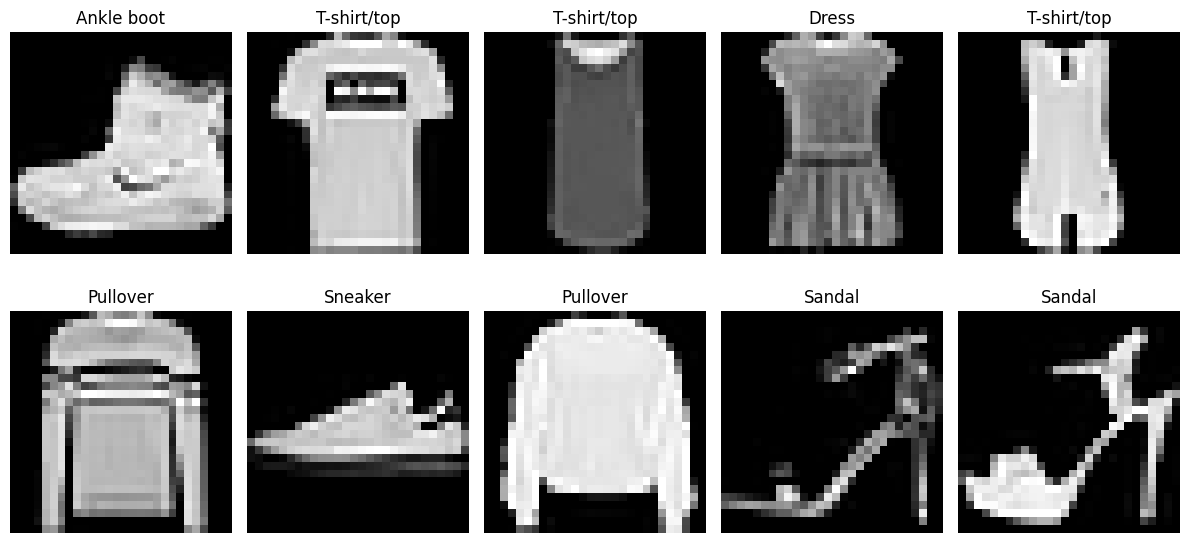

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Тип даних навчальної вибірки:", x_train.dtype)
print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())

print("\nТип даних тестової вибірки:", x_test.dtype)
print("Мінімальне значення:", x_test.min())
print("Максимальне значення:", x_test.max())

Тип даних навчальної вибірки: float32
Мінімальне значення: 0.0
Максимальне значення: 1.0

Тип даних тестової вибірки: float32
Мінімальне значення: 0.0
Максимальне значення: 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:

model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:

from sklearn.model_selection import train_test_split

x_train_part, x_val, y_train_part, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    x_train_part,
    y_train_part,
    epochs=50,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7771 - loss: 0.6284 - val_accuracy: 0.8576 - val_loss: 0.3954 - learning_rate: 0.0010
Epoch 2/50
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8412 - loss: 0.4418 - val_accuracy: 0.8698 - val_loss: 0.3655 - learning_rate: 0.0010
Epoch 3/50
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8556 - loss: 0.3982 - val_accuracy: 0.8771 - val_loss: 0.3359 - learning_rate: 0.0010
Epoch 4/50
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8631 - loss: 0.3746 - val_accuracy: 0.8753 - val_loss: 0.3405 - learning_rate: 0.0010
Epoch 5/50
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8698 - loss: 0.3580 - val_accuracy: 0.8806 - val_loss: 0.3218 - learning_rate: 0.0010
Epoch 6/50
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8745 - loss: 0.3425 - val_accuracy: 0.8846 - val_loss: 0.3137 - learning_rate: 0.0010
Epoch 7/50
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8797 - loss: 0.3281 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:

model.summary()

print("\nКількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

trainable_params = sum(
    tf.size(weight).numpy()
    for weight in model.trainable_weights
)
print("Навчувані параметри:", trainable_params)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Кількість шарів: 6
Загальна кількість параметрів: 235146
Навчувані параметри: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [10]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
model.save('/content/drive/MyDrive/fashion_mnist_model.keras')

print("Модель успішно збережено!")

Модель успішно збережено!


In [12]:
import os

file_path = '/content/drive/MyDrive/fashion_mnist_model.keras'

print("Файл існує:", os.path.exists(file_path))

Файл існує: True


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

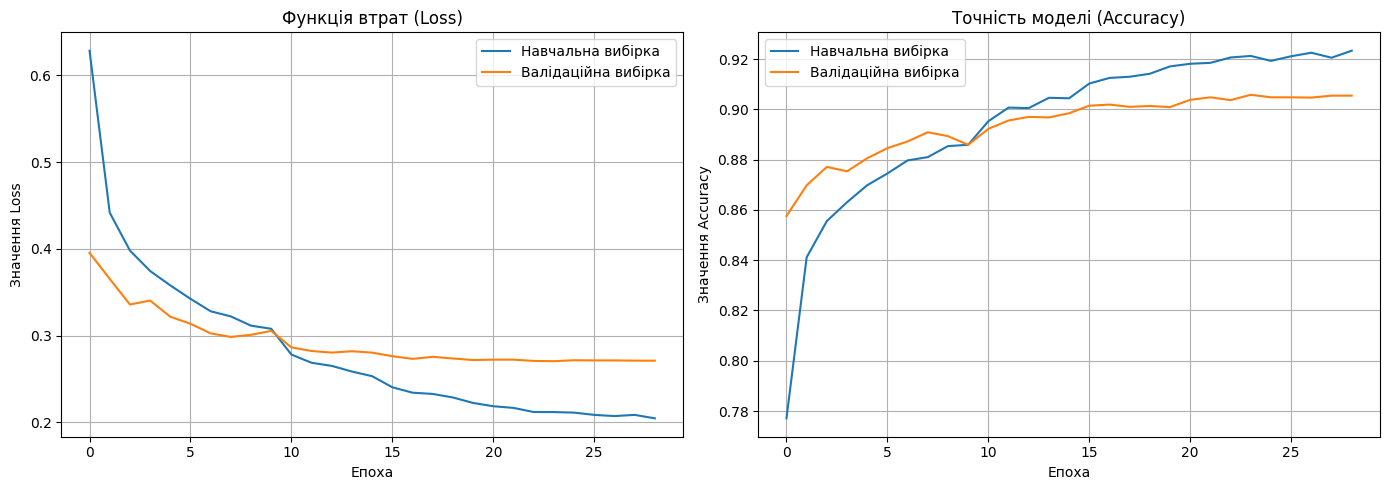

In [13]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:

plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Навчальна вибірка')
plt.plot(history.history['val_loss'], label='Валідаційна вибірка')
plt.title('Функція втрат (Loss)')
plt.xlabel('Епоха')
plt.ylabel('Значення Loss')
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Навчальна вибірка')
plt.plot(history.history['val_accuracy'], label='Валідаційна вибірка')
plt.title('Точність моделі (Accuracy)')
plt.xlabel('Епоха')
plt.ylabel('Значення Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [14]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)

print("\nРезультати оцінювання:")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

y_pred_prob = model.predict(x_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print("\nКласифікаційний звіт:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

if test_accuracy >= 0.87:
    print("Модель досягла необхідної точності 0.87!")
else:
    print("Модель не досягла необхідної точності 0.87.")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8936 - loss: 0.3089

Результати оцінювання:
Test Loss: 0.3089
Test Accuracy: 0.8936
Test Accuracy (%): 89.36 %
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8444    0.8520    0.8482      1000
     Trouser     0.9868    0.9730    0.9799      1000
    Pullover     0.8136    0.7990    0.8063      1000
       Dress     0.8839    0.8980    0.8909      1000
        Coat     0.7998    0.8310    0.8151      1000
      Sandal     0.9798    0.9720    0.9759      1000
       Shirt     0.7304    0.7070    0.7185      1000
     Sneaker     0.9481    0.9690    0.9585      1000
         Bag     0.9790    0.9770    0.9780      1000
  Ankle boot     0.9696    0.9580    0.9638      1000

    accuracy                         0.8936     10000
   macro avg     0.8935    0.8936    0.8935     10000
weighted avg     0.8935    0.8936    0.8935     10000

Модель дося

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

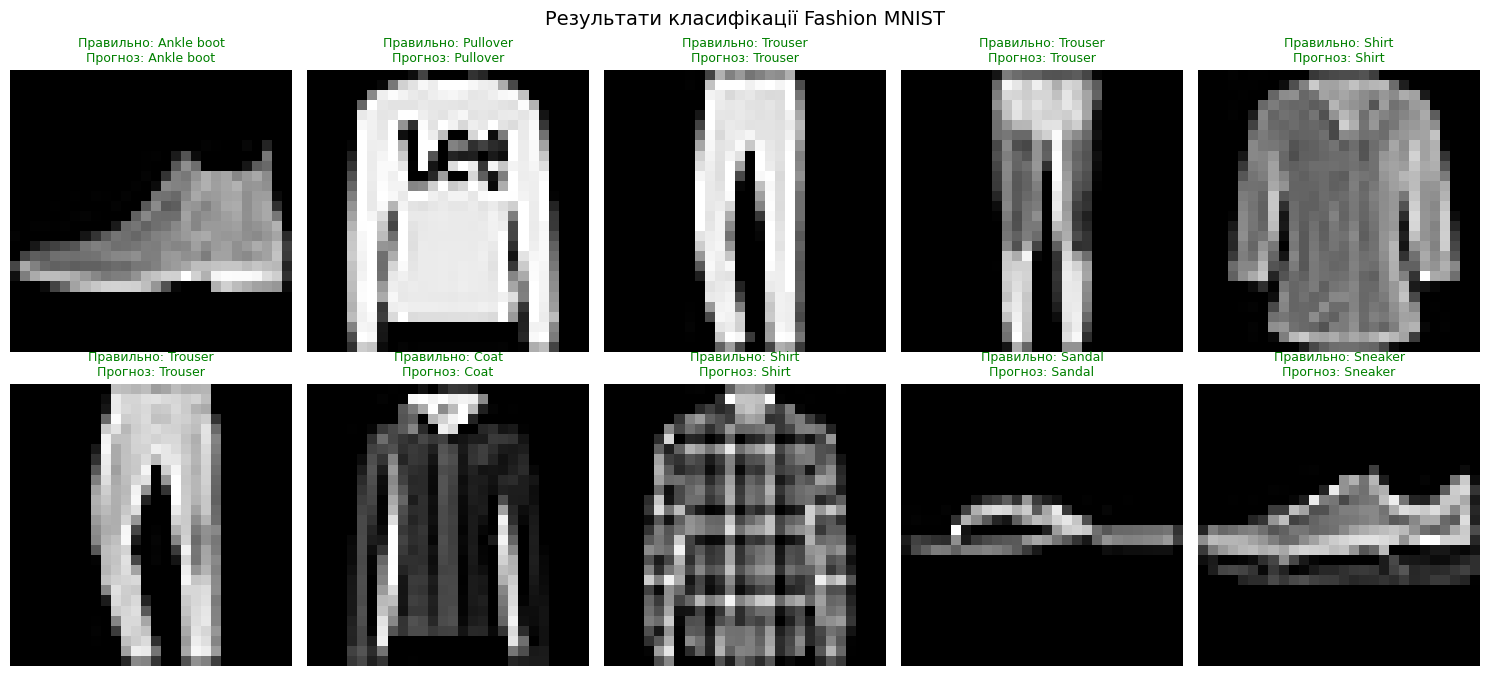

In [15]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:

plt.figure(figsize=(15, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    true_label = class_names[y_test[i]]
    predicted_label = class_names[y_pred[i]]

    color = 'green' if y_test[i] == y_pred[i] else 'red'

    plt.title(
        f'Правильно: {true_label}\nПрогноз: {predicted_label}',
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.suptitle('Результати класифікації Fashion MNIST', fontsize=14)
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  

Точність моделі на тестовій вибірці становить 89,36%, що перевищує встановлену вимогу 87%. Найбільше помилок модель допускає під час розпізнавання сорочок (Shirt), светрів (Pullover) та пальт (Coat), оскільки ці предмети одягу мають схожі візуальні ознаки. Найкраще модель розпізнає штани, сумки та сандалії. Отже, модель досягла необхідної точності та успішно виконала завдання класифікації Fashion MNIST.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [16]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:

!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

print("Keras Tuner:", kt.__version__)
print("Імпорти виконано успішно!")

Keras Tuner: 1.4.8
Імпорти виконано успішно!


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [17]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:

x_train_tuner, x_val_tuner, y_train_tuner, y_val_tuner = train_test_split(
    x_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("Навчальна вибірка:", x_train_tuner.shape)
print("Валідаційна вибірка:", x_val_tuner.shape)
print("Тестова вибірка:", x_test.shape)

print("\nМітки навчальної вибірки:", y_train_tuner.shape)
print("Мітки валідаційної вибірки:", y_val_tuner.shape)
print("Мітки тестової вибірки:", y_test.shape)

Навчальна вибірка: (51000, 28, 28)
Валідаційна вибірка: (9000, 28, 28)
Тестова вибірка: (10000, 28, 28)

Мітки навчальної вибірки: (51000,)
Мітки валідаційної вибірки: (9000,)
Мітки тестової вибірки: (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [20]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:

def build_model(hp):
    model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    Flatten()
])

    num_layers = hp.Int('num_layers', min_value=1, max_value=3)

    for i in range(num_layers):
        units = hp.Int(
            f'units_{i}',
            min_value=32,
            max_value=512,
            step=32
        )

        model.add(Dense(
            units=units,
            activation='relu',
            kernel_regularizer=l2(0.001)
        ))

        dropout_rate = hp.Float(
            f'dropout_{i}',
            min_value=0.1,
            max_value=0.5,
            step=0.1
        )
        model.add(Dropout(dropout_rate))

    model.add(Dense(10, activation='softmax'))

    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.01, 0.001, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [21]:
# Ініціалізуйте RandomSearch.
# Ваш код:

tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='fashion_mnist_tuning',
    project_name='fashion_mnist'
)

tuner.search_space_summary()

Search space summary
Default search space size: 4
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [22]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:

early_stopping_tuner = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_tuner = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

tuner.search(
    x_train_tuner,
    y_train_tuner,
    validation_data=(x_val_tuner, y_val_tuner),
    epochs=30,
    batch_size=128,
    callbacks=[early_stopping_tuner, reduce_lr_tuner],
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nНайкращі гіперпараметри:")
print("Кількість прихованих шарів:", best_hp.get('num_layers'))

for i in range(best_hp.get('num_layers')):
    print(f"Кількість нейронів у шарі {i + 1}:",
          best_hp.get(f'units_{i}'))
    print(f"Dropout у шарі {i + 1}:",
          best_hp.get(f'dropout_{i}'))

print("Швидкість навчання:", best_hp.get('learning_rate'))

best_model = build_model(best_hp)

best_model.summary()

history_tuner = best_model.fit(
    x_train_tuner,
    y_train_tuner,
    validation_data=(x_val_tuner, y_val_tuner),
    epochs=30,
    batch_size=128,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=0.00001
        )
    ],
    verbose=1
)

print("\nКількість епох повторного навчання:",
      len(history_tuner.history['loss']))

print("Найкраща точність на валідації:",
      max(history_tuner.history['val_accuracy']))

Trial 3 Complete [00h 03m 28s]
val_accuracy: 0.828000009059906

Best val_accuracy So Far: 0.8914444446563721
Total elapsed time: 00h 06m 34s

Найкращі гіперпараметри:
Кількість прихованих шарів: 3
Кількість нейронів у шарі 1: 128
Dropout у шарі 1: 0.1
Кількість нейронів у шарі 2: 448
Dropout у шарі 2: 0.1
Кількість нейронів у шарі 3: 32
Dropout у шарі 3: 0.1
Швидкість навчання: 0.0001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 448)            │        57,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │        14,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,970 (675.66 KB)

 Trainable params: 172,970 (675.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.6252 - loss: 1.5686 - val_accuracy: 0.7961 - val_loss: 1.0444 - learning_rate: 1.0000e-04
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7859 - loss: 1.0553 - val_accuracy: 0.8301 - val_loss: 0.8971 - learning_rate: 1.0000e-04
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8130 - loss: 0.9377 - val_accuracy: 0.8419 - val_loss: 0.8322 - learning_rate: 1.0000e-04
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8279 - loss: 0.8722 - val_accuracy: 0.8527 - val_loss: 0.7795 - learning_rate: 1.0000e-04
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8383 - loss: 0.8199 - val_accuracy: 0.8606 - val_loss: 0.7404 - learning_rate: 1.0000e-04
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8438 - loss: 0.7816 - val_accuracy: 0.8636 - val_loss: 0.7147 - learning_rate: 1.0000e-04
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8786 - loss: 0.4938

Результати оцінювання найкращої моделі:
Test Loss: 0.4938
Test Accuracy: 0.8786
Test Accuracy (%): 87.86 %


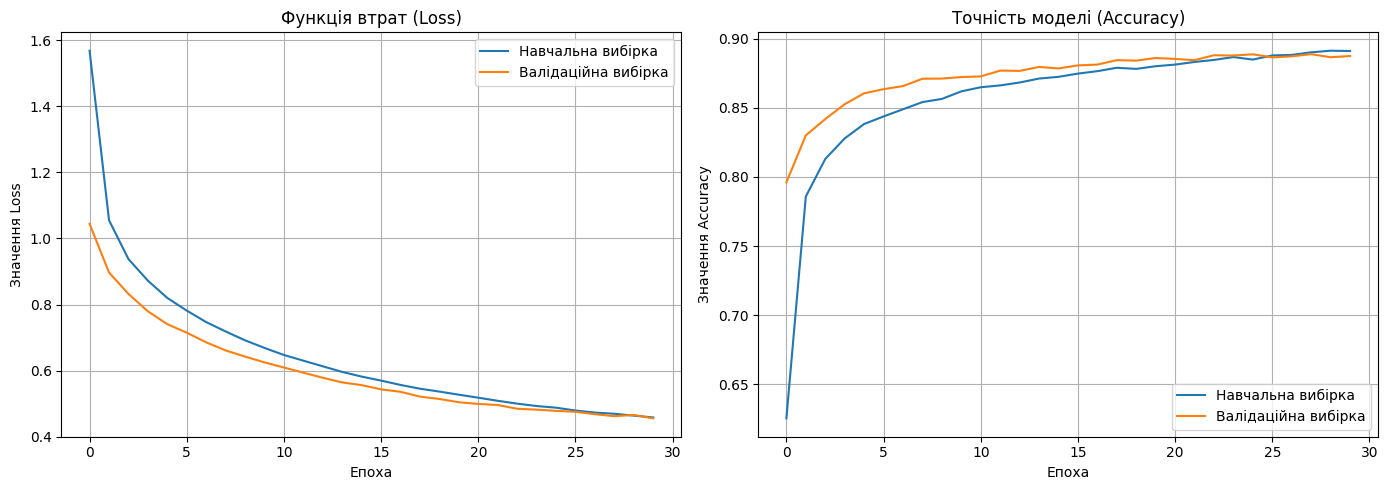

In [23]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:

test_loss, test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nРезультати оцінювання найкращої моделі:")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

# Побудова графіків навчання
plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)
plt.plot(history_tuner.history['loss'], label='Навчальна вибірка')
plt.plot(history_tuner.history['val_loss'], label='Валідаційна вибірка')
plt.title('Функція втрат (Loss)')
plt.xlabel('Епоха')
plt.ylabel('Значення Loss')
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(history_tuner.history['accuracy'], label='Навчальна вибірка')
plt.plot(history_tuner.history['val_accuracy'], label='Валідаційна вибірка')
plt.title('Точність моделі (Accuracy)')
plt.xlabel('Епоха')
plt.ylabel('Значення Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| **Показник** | **Модель із завдання 1** | **Модель після Keras Tuner** |
|---|---:|---:|
| Кількість прихованих шарів | 2 | 3 |
| Кількість нейронів | 256, 128 | 128, 448, 32 |
| Швидкість навчання | 0.001 | 0.0001 |
| Точність на тестовій вибірці (accuracy) | 0.8936 | Потрібен результат тестування |
| Втрати на тестовій вибірці (loss) | 0.3089 | Потрібен результат тестування |
| Кількість епох навчання | Потрібен точний результат | 30 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
У першому завданні модель досягла точності 89,36%, що перевищує необхідний показник 87%. За допомогою Keras Tuner було підібрано три приховані шари з 128, 448 і 32 нейронами, Dropout 0,1 та швидкість навчання 0,0001. Найкраща точність на валідаційній вибірці після повторного навчання становила 88,89%.

Результати можуть відрізнятися між запусками через випадкову ініціалізацію ваг і особливості навчання. Найскладніше першій моделі було класифікувати сорочки, светри та пальта через схожість їхніх зображень.


---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.